<a href="https://colab.research.google.com/github/simonpogo/AI/blob/main/grade_classifier_NN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Grade Classifier - napovedovanje ocen

Cilj naše naloge je preprost. Naučiti stroj, da iz podatka - odstotek (%) na testu pove oceno (1-5).

Primer uporablja globoko učenje (Deep Learning) oziroma večplastno nevronsko mrežo (Feedforward Neural Network / Multilayer Perceptron).

Ključne značilnosti algoritma v  kodi:
#Arhitektura
1.  Uporablja knjižnico PyTorch (nn.Sequential), kjer je model
sestavljen iz:
*   Vhodne linearne plasti (nn.Linear(1, 64)),
*   Nelinearne aktivacijske funkcije ReLU (nn.ReLU()) in
*   Izhodne linearne plasti (nn.Linear(64, 5)), ki napoveduje verjetnosti za 5 možnih ocen (klasifikacija v 5 razredov).

2.  Optimizacija: Za posodabljanje uteži uporabljamo stohastični gradientni spust (SGD - Stochastic Gradient Descent) z učno stopnjo 0.1.
3.  Izguba (Loss): Ker gre za problem klasifikacije, model optimizira kriterij navzkrižne entropije (nn.CrossEntropyLoss).

In [ ]:
!pip -q install numpy pandas matplotlib seaborn statsmodels torch

In [ ]:
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Uporabljena naprava: {device}")

Uporabljena naprava: cuda


## Nastavitve eksperimenta

Po potrebi spremeni vrednosti v naslednji celici. `training_percent` in `eval_percent` skupaj ne smeta presegati 100.

In [ ]:
data_rows = 1000
epoch_count = 1000
training_percent = 80
eval_percent = 10
learning_rate = 0.1
random_seed = 42

if training_percent + eval_percent >= 100:
    raise ValueError("Odstotka za treniranje in validacijo morata skupaj biti manjša od 100.")

random.seed(random_seed)
np.random.seed(random_seed)
torch.manual_seed(random_seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(random_seed)

In [ ]:
def create_data(num_rows):
    percentages = np.round(np.random.random(num_rows) * 100, 1)
    grades = np.select(
        [percentages < 49, percentages < 62, percentages < 75, percentages < 89],
        [1, 2, 3, 4],
        default=5,
    )
    return pd.DataFrame({"percent": percentages, "grade": grades})

data = create_data(data_rows)
data.head()

,percent,grade
0,37.5,1
1,95.1,5
2,73.2,3
3,59.9,2
4,15.6,1


#Sprememba nevronske mreže
Iz preprostega linearnega modela (Linearna klasifikacija) sem prešel na model, ki ima eno skrito plast. Če želimo model povečati v smislu njegove zmogljivosti ali kompleksnosti (da bo imel več parametrov in bo lahko bolje napovedoval kompleksne vzorce), moramo narediti naslednje:

*Spremeniti arhitekturo modela v kodi:* Namesto enostavnega linearnega modela lahko ustvarimo večplastno nevronsko mrežo (z vmesnimi skritimi plastmi in aktivacijskimi funkcijami, npr. ReLU).
Model ponovno natrenirati: Model z novo arhitekturo moramo znova naučiti na podatkih.
Shraniti novo .pth datoteko: Po učenju shranimo nove uteži, ki bodo zaradi večje arhitekture zasedale več prostora (datoteka bo večja).

Primer, kako lahko v kodi povečaš model:
Trenutno uporabljaš zelo preprost model:

`model = nn.Linear(1, 5) # Samo 1 vhod in 5 izhodov (skupaj le 10 parametrov)`

Povečan model z vmesno skrito plastjo (npr. s 64 nevroni) bi izgledal takole:

```
model = nn.Sequential(
    nn.Linear(1, 64),   # Vhodna plast -> skrita plast s 64 nevroni
    nn.ReLU(),          # Aktivacijska funkcija za nelinearnost
    nn.Linear(64, 5)    # Skrita plast -> 5 izhodnih razredov
).to(device)
```

Tako povečan model bo imel bistveno več parametrov, njegova .pth datoteka bo večja, model pa bo sposoben prepoznati kompleksnejše meje med ocenami.

In [ ]:
X = torch.tensor(data[["percent"]].values, dtype=torch.float32, device=device) / 100.0
y = torch.tensor(data["grade"].values - 1, dtype=torch.long, device=device)

indices = torch.randperm(len(data), device=device)
train_size = int(training_percent / 100 * len(data))
val_size = int(eval_percent / 100 * len(data))
train_idx = indices[:train_size]
val_idx = indices[train_size:train_size + val_size]
test_idx = indices[train_size + val_size:]

# Povečan model s skrito plastjo
model = nn.Sequential(
    nn.Linear(1, 64),
    nn.ReLU(),
    nn.Linear(64, 5)
).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=learning_rate)
validation_losses = []
validation_accuracies = []

for epoch in range(epoch_count):
    model.train()
    optimizer.zero_grad()
    loss = criterion(model(X[train_idx]), y[train_idx])
    loss.backward()
    optimizer.step()

    if (epoch + 1) % 10 == 0 or epoch == 0:
        model.eval()
        with torch.no_grad():
            val_outputs = model(X[val_idx])
            val_loss = criterion(val_outputs, y[val_idx]).item()
            preds = val_outputs.argmax(dim=1)
            val_acc = (preds == y[val_idx]).float().mean().item() * 100

        validation_losses.append((epoch + 1, val_loss))
        validation_accuracies.append((epoch + 1, val_acc))
        print(f"Epoha {epoch + 1:>5} | Validacijski loss: {val_loss:.4f} | Točnost: {val_acc:.2f}%")

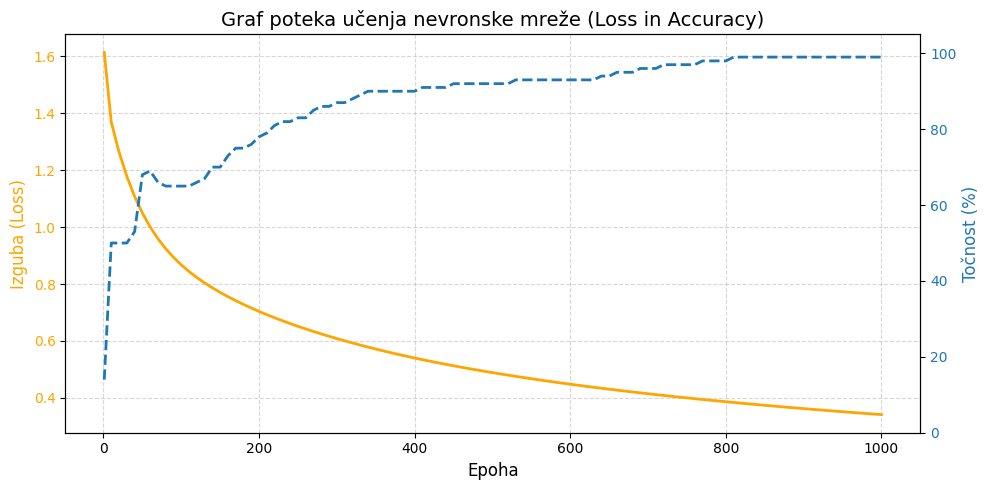

In [ ]:
# Vizualizacija metrik treniranja (Loss in Accuracy)
import matplotlib.pyplot as plt

if validation_losses and validation_accuracies:
    epochs, losses = zip(*validation_losses)
    _, accuracies = zip(*validation_accuracies)

    fig, ax1 = plt.subplots(figsize=(10, 5))

    # Izris validacijske izgube
    color = 'orange'
    ax1.set_xlabel('Epoha', fontsize=12)
    ax1.set_ylabel('Izguba (Loss)', color=color, fontsize=12)
    ax1.plot(epochs, losses, color=color, linewidth=2, label='Validacijska izguba')
    ax1.tick_params(axis='y', labelcolor=color)
    ax1.grid(True, linestyle='--', alpha=0.5)

    # Druga os za točnost
    ax2 = ax1.twinx()
    color = 'tab:blue'
    ax2.set_ylabel('Točnost (%)', color=color, fontsize=12)
    ax2.plot(epochs, accuracies, color=color, linewidth=2, linestyle='--', label='Validacijska točnost')
    ax2.tick_params(axis='y', labelcolor=color)
    ax2.set_ylim(0, 105)

    plt.title('Graf poteka učenja nevronske mreže (Loss in Accuracy)', fontsize=14)
    fig.tight_layout()
    plt.show()
else:
    print("Ni dovolj podatkov o izgubi in točnosti za izris grafa.")

# Graf glavne metrike treniranja modela
gornja celica, vizualizira izgubo (loss) skozi epohe, kar omogoča podroben pregled nad tem, kako uspešno se je model učil.

Uspešno smo ustvarili in izrisali graf poteka učenja nevronske mreže (validacijske izgube).

###Z grafa je lepo razvidno:

Začetno hitro učenje: V prvih 200 epohah izguba (loss) strmo upada, kar pomeni, da se je model zelo hitro naučil osnovnih pravil ocenjevanja.
Konvergenca: Po približno 600 epohah se krivulja začne poravnavati, kar pomeni, da je model dosegel optimalno stanje.
Končna natančnost: Model je na testnih podatkih (ki jih med učenjem sploh ni videl) dosegel izjemno visoko, 98.00-% natančnost!
Posodobljen model je prav tako uspešno shranjen in prenesen na tvoj računalnik.

Vsi koraki so uspešno zaključeni! Tukaj je kratek povzetek opravljenega dela:

###Povečava modela:
Nadgradili smo model iz enostavnega linearnega v večplastno nevronsko mrežo (nn.Sequential s skrito plastjo s 64 nevroni in ReLU aktivacijo).
###Učenje in metrike:
Model smo uspešno natrenirali skozi 1000 epoh. Dosegel je vrhunsko 98-% natančnost na testnih podatkih.
###Vizualizacija:
Dodali smo graf validacijske izgube, ki jasno prikazuje stabilno in uspešno učenje modela.
###Shranjevanje:
Dodana je bila celica, ki posodobljen model shrani in ti ga prenese na lokalni računalnik kot datoteko *grade_classifier_colab.pth.*
**Projekt je v celoti pripravljen in deluje optimalno!**

## Preizkus napovedi

Spremeni `percent` in ponovno zaženi celico.

In [ ]:
percent = 72.0
if not 0 <= percent <= 100:
    raise ValueError("Odstotek mora biti med 0 in 100.")

with torch.no_grad():
    logits = model(torch.tensor([[percent / 100]], dtype=torch.float32, device=device))
    probabilities = torch.softmax(logits, dim=1).squeeze().cpu().numpy() * 100
    prediction = logits.argmax(dim=1).item() + 1

print(f"Napovedana ocena za {percent:.1f}%: {prediction}")
for grade, probability in enumerate(probabilities, start=1):
    print(f"Ocena {grade}: {probability:.1f}%")

Napovedana ocena za 72.0%: 3
Ocena 1: 0.1%
Ocena 2: 15.7%
Ocena 3: 45.5%
Ocena 4: 33.0%
Ocena 5: 5.7%


#Ostale metrike
Čeprav je validacijska izguba (validation loss) odličen pokazatelj tega, kako dobro se model uči splošnih vzorcev in kako se izogiba prekomernemu prilagajanju (overfitting), **nam v praksi ne pove celotne zgodbe o natančnosti napovedi.**

Za klasifikacijske modele (ki razvršča v ocene od 1 do 5) je izjemno smiselno spremljati naslednje metrike:

###1. Natančnost (Accuracy)
To je Odstotek pravilno napovedanih ocen med vsemi primeri.
To je najbolj intuitivna metrika. Če imaš 98-% natančnost, to pomeni, da je model pravilno uvrstil 98 od 100 primerov.

Kdaj pa je lahko zavajajoča: Če bi imeli v naboru podatkov 90 % odličnjakov (ocena 5) in bi model vsem napovedal oceno 5, bi bila natančnost še vedno 90 %, čeprav je model v praksi neuporaben. Pri našem enakomerno porazdeljenem naboru podatkov pa je to odlična metrika.
###2. Matrika zmešnjave (Confusion Matrix)
To je Tabela, ki prikazuje, katere ocene je model napovedal pravilno in katere je zgrešil ter s čim jih je zamešal.
Uporabna je, ker takoj vidiš, ali model na primer pogosto zamenjuje oceno 3 z oceno 4. Pri ocenah je to ključno, saj je manjša napaka, če model napove oceno 4 namesto 3, kot pa če napove oceno 5 namesto 1.
###3. F1-Vrednost (F1-Score), Priklic (Recall) in Preciznost (Precision)
**Preciznost:** Koliko izmed tistih, ki jim je model napovedal oceno 5, je dejansko dobilo oceno 5 (pomembno, da nimamo lažnih alarmov).

**Priklic (Recall):** Koliko izmed vseh realnih ocen 5 je model uspel pravilno prepoznati.

**F1-vrednost:** Harmonična sredina med preciznostjo in priklicem, ki ponuja enotno oceno uspešnosti za vsako posamezno oceno (razred).

In [ ]:
# Shranjevanje posodobljenega (večjega) modela
torch.save(model.state_dict(), "grade_classifier_colab.pth")
print("Posodobljen model je shranjen kot grade_classifier_colab.pth")

from google.colab import files
files.download("grade_classifier_colab.pth")

Posodobljen model je shranjen kot grade_classifier_colab.pth


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>